# Прогноз оттока клиентов: SQL-аналитика + ML

**Задача:** по данным телеком-оператора найти клиентов, которые скорее всего уйдут, и решить,
кому выгодно предложить удерживающую скидку.

**Пайплайн:** сырые данные → таблица в БД → SQL-аналитика и витрина признаков (`sql/`) →
модели scikit-learn → выбор порога по экономике удержания.

Данные: [Telco Customer Churn](https://www.openml.org/d/42178) (7043 клиента, 20 признаков).
БД: SQLite из стандартной библиотеки, запросы написаны на стандартном SQL (CTE, оконные функции)
и без изменений выполняются в PostgreSQL.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve
from sklearn.inspection import permutation_importance

SEED = 42
SQL_DIR = Path("sql")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

def read_sql(name):
    return (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")

## 1. Загрузка данных в БД

In [2]:
raw = fetch_openml(data_id=42178, as_frame=True, data_home="data").frame
# в выгрузке OpenML часть строковых значений обёрнута в кавычки: 'One year' -> One year
raw = raw.apply(lambda s: s.str.strip("'") if s.dtype == object or str(s.dtype) == "str" else s)
raw["TotalCharges"] = pd.to_numeric(raw["TotalCharges"], errors="coerce")   # пробел у новых клиентов -> NaN
raw["Churn"] = (raw["Churn"] == "Yes").astype(int)

cols = ["gender", "senior_citizen", "partner", "dependents", "tenure", "phone_service",
        "multiple_lines", "internet_service", "online_security", "online_backup",
        "device_protection", "tech_support", "streaming_tv", "streaming_movies", "contract",
        "paperless_billing", "payment_method", "monthly_charges", "total_charges", "churn"]
raw.columns = cols
raw.insert(0, "customer_id", np.arange(1, len(raw) + 1))
raw = raw.astype(object).where(raw.notna(), None)      # NaN -> NULL

con = sqlite3.connect(":memory:")
con.executescript(read_sql("schema"))
con.executemany(f"INSERT INTO customers VALUES ({','.join('?' * raw.shape[1])})",
                raw.itertuples(index=False, name=None))
q = lambda sql: pd.read_sql_query(sql, con)
q("SELECT COUNT(*) AS rows, SUM(churn) AS churned, 100.0 * AVG(churn) AS churn_rate_pct, "
  "SUM(CASE WHEN total_charges IS NULL THEN 1 ELSE 0 END) AS null_total_charges FROM customers").round(2)

,rows,churned,churn_rate_pct,null_total_charges
0,7043,1869,26.54,11


## 2. SQL-аналитика

### Отток по типу контракта ([`sql/churn_by_contract.sql`](sql/churn_by_contract.sql))

In [3]:
by_contract = q(read_sql("churn_by_contract"))
by_contract.round(1)

,contract,customers,churned,churn_rate_pct,lost_mrr,share_of_lost_mrr_pct
0,Month-to-month,3875,1655,42.7,120847.1,86.9
1,One year,1473,166,11.3,14118.4,10.1
2,Two year,1695,48,2.8,4165.3,3.0


### Отток по стажу клиента ([`sql/churn_by_tenure.sql`](sql/churn_by_tenure.sql))

,tenure_group,customers,churned,churn_rate_pct,cumulative_churned_pct
0,01: 0-6 мес,1481,784,52.9,41.9
1,02: 7-12 мес,705,253,35.9,55.5
2,03: 1-2 года,1024,294,28.7,71.2
3,04: 2-4 года,1594,325,20.4,88.6
4,05: 4+ года,2239,213,9.5,100.0


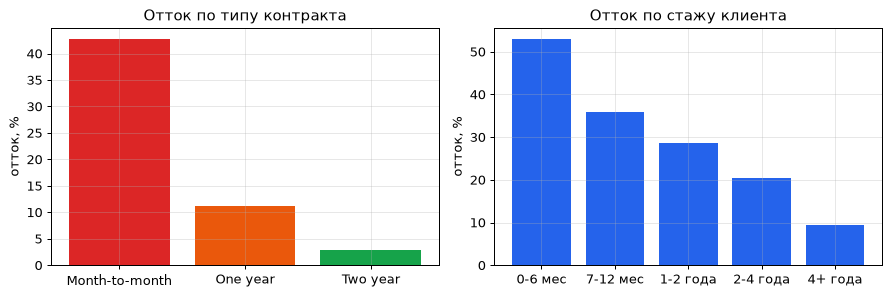

In [4]:
by_tenure = q(read_sql("churn_by_tenure"))
display(by_tenure.round(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(by_contract["contract"], by_contract["churn_rate_pct"], color=["#dc2626", "#ea580c", "#16a34a"])
ax[0].set_ylabel("отток, %"); ax[0].set_title("Отток по типу контракта")
ax[1].bar(by_tenure["tenure_group"].str[4:], by_tenure["churn_rate_pct"], color="#2563eb")
ax[1].set_ylabel("отток, %"); ax[1].set_title("Отток по стажу клиента")
plt.tight_layout(); plt.savefig("images/sql_churn_segments.png", bbox_inches="tight"); plt.show()

### Самые рискованные сегменты ([`sql/top_segments.sql`](sql/top_segments.sql))

In [5]:
q(read_sql("top_segments")).round(1)

,contract,internet_service,payment_method,customers,churn_rate_pct,risk_rank
0,Month-to-month,Fiber optic,Electronic check,1307,60.4,1
1,Month-to-month,Fiber optic,Mailed check,201,50.7,2
2,Month-to-month,Fiber optic,Bank transfer (automatic),327,45.6,3
3,Month-to-month,Fiber optic,Credit card (automatic),293,41.6,4
4,Month-to-month,DSL,Electronic check,474,40.5,5


## 3. Витрина признаков ([`sql/features.sql`](sql/features.sql))

Признаки считаются в SQL-представлении `customer_features`: число доп. услуг, средний платёж,
рост платежа относительно среднего, флаги. Python забирает готовую таблицу.

In [6]:
con.executescript(read_sql("features"))
feat = q("SELECT * FROM customer_features")
X, y = feat.drop(columns=["customer_id", "churn"]), feat["churn"]
X["avg_monthly_spend"] = X["avg_monthly_spend"].fillna(X["monthly_charges"])   # tenure = 0
cat_cols = ["contract", "internet_service", "payment_method", "multiple_lines"]
num_cols = [c for c in X.columns if c not in cat_cols]
print(X.shape, "| категориальные:", cat_cols)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print("train", X_tr.shape, "test", X_te.shape, "| доля оттока в test:", round(y_te.mean(), 3))

(7043, 15) | категориальные: ['contract', 'internet_service', 'payment_method', 'multiple_lines']
train (5282, 15) test (1761, 15) | доля оттока в test: 0.265


## 4. Модели

Сравниваем три модели на 5-фолдовой стратифицированной кросс-валидации. Классы несбалансированы
(~27% оттока), поэтому кроме ROC-AUC смотрим PR-AUC (average precision).

In [7]:
prep = ColumnTransformer([("num", StandardScaler(), num_cols),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
models = {
    "LogReg": make_pipeline(prep, LogisticRegression(max_iter=2000, C=0.5)),
    "RandomForest": make_pipeline(prep, RandomForestClassifier(n_estimators=400, min_samples_leaf=10,
                                                              random_state=SEED, n_jobs=-1)),
    "HistGradBoosting": make_pipeline(prep, HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                                          max_leaf_nodes=15, l2_regularization=1.0,
                                                                          early_stopping=True, random_state=SEED)),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    r = cross_validate(m, X_tr, y_tr, cv=cv, scoring=["roc_auc", "average_precision"])
    m.fit(X_tr, y_tr); p = m.predict_proba(X_te)[:, 1]
    rows.append({"модель": name,
                 "CV ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                 "CV PR-AUC": f"{r['test_average_precision'].mean():.3f} ± {r['test_average_precision'].std():.3f}",
                 "test ROC-AUC": roc_auc_score(y_te, p), "test PR-AUC": average_precision_score(y_te, p)})
results = pd.DataFrame(rows).set_index("модель")
results.round(3)

,CV ROC-AUC,CV PR-AUC,test ROC-AUC,test PR-AUC
модель,,,,
LogReg,0.843 ± 0.015,0.662 ± 0.039,0.848,0.641
RandomForest,0.845 ± 0.013,0.668 ± 0.032,0.848,0.652
HistGradBoosting,0.843 ± 0.013,0.665 ± 0.033,0.850,0.646


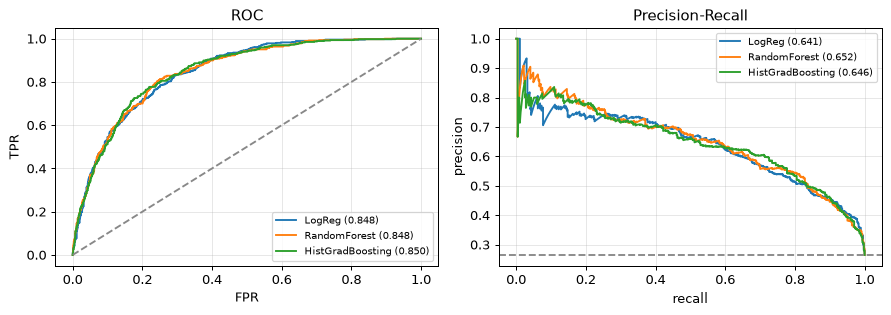

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for name, m in models.items():
    p = m.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p); pr, rc, _ = precision_recall_curve(y_te, p)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_te, p):.3f})")
    ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], "--", c="#888"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC")
ax[1].axhline(y_te.mean(), ls="--", c="#888"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-Recall")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/roc_pr.png", bbox_inches="tight"); plt.show()

## 5. Порог по экономике удержания

Порог 0.5 не связан с бизнесом. Зададим простую модель (допущения явные, их легко поменять):

- клиенту из группы риска предлагаем скидку стоимостью **1 месячный платёж** (`OFFER_COST`);
- предложение удерживает **30%** действительно уходящих клиентов (`SUCCESS`);
- удержанный клиент приносит ещё **12 месяцев** выручки (`HORIZON`).

Предложение клиенту с вероятностью ухода $p$ окупается, если $p \cdot SUCCESS \cdot HORIZON > OFFER\_COST$,
то есть теоретический порог $p^* = OFFER\_COST / (SUCCESS \cdot HORIZON) \approx 0.28$ — если вероятности модели
откалиброваны. Проверим это эмпирически: порог подбираем по **out-of-fold** предсказаниям на train,
а test используем только для итоговой оценки (без подглядывания).

модель: RandomForest | клиентов в test: 1761


,порог,предложений,recall оттока,"прибыль на test, USD"
0,0.50 (по умолчанию),330,0.480,37394.26
1,0.28 (теоретический p*),699,0.809,50287.53
2,0.32 (подобран на OOF),637,0.760,49597.14


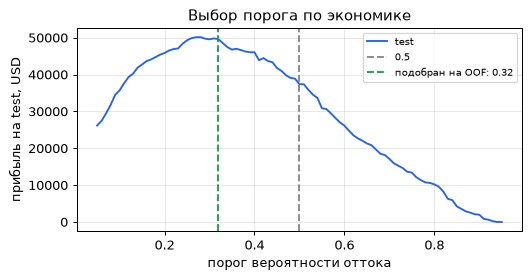

In [9]:
OFFER_COST, SUCCESS, HORIZON = 1, 0.30, 12
best_name = results["CV PR-AUC"].str[:5].astype(float).idxmax()      # выбор модели — по CV, не по test
best = models[best_name]
p_oof = cross_val_predict(best, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
p_te = best.predict_proba(X_te)[:, 1]

def profit(p, y, mrr, th):
    target = p >= th
    return (SUCCESS * HORIZON * mrr * (target & (y == 1))).sum() - (OFFER_COST * mrr * target).sum()

ths = np.linspace(0.05, 0.95, 91)
prof_oof = np.array([profit(p_oof, y_tr.to_numpy(), X_tr["monthly_charges"].to_numpy(), t) for t in ths])
th_star = OFFER_COST / (SUCCESS * HORIZON)
th_oof = ths[prof_oof.argmax()]

yt, mrr_te = y_te.to_numpy(), X_te["monthly_charges"].to_numpy()
summary = pd.DataFrame({
    "порог": ["0.50 (по умолчанию)", f"{th_star:.2f} (теоретический p*)", f"{th_oof:.2f} (подобран на OOF)"],
    "предложений": [(p_te >= t).sum() for t in (0.5, th_star, th_oof)],
    "recall оттока": [((p_te >= t) & (yt == 1)).sum() / yt.sum() for t in (0.5, th_star, th_oof)],
    "прибыль на test, USD": [profit(p_te, yt, mrr_te, t) for t in (0.5, th_star, th_oof)],
})
print("модель:", best_name, "| клиентов в test:", len(yt))
display(summary.round(3))

prof_te = np.array([profit(p_te, yt, mrr_te, t) for t in ths])
plt.figure(figsize=(6, 3.2))
plt.plot(ths, prof_te, c="#2563eb", label="test")
plt.axvline(0.5, ls="--", c="#888", label="0.5")
plt.axvline(th_oof, ls="--", c="#16a34a", label=f"подобран на OOF: {th_oof:.2f}")
plt.xlabel("порог вероятности оттока"); plt.ylabel("прибыль на test, USD"); plt.title("Выбор порога по экономике")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("images/profit_threshold.png", bbox_inches="tight"); plt.show()

## 6. Что влияет на отток

Permutation importance лучшей модели на test: насколько падает PR-AUC, если перемешать признак.

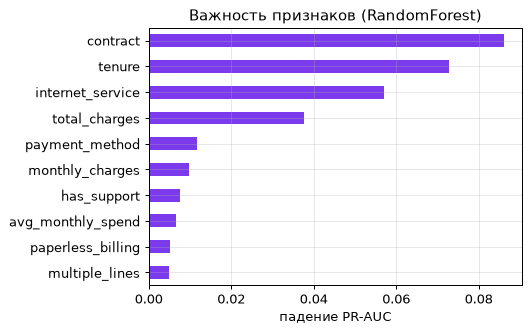

contract             0.0862
tenure               0.0727
internet_service     0.0570
total_charges        0.0376
payment_method       0.0117
monthly_charges      0.0098
has_support          0.0076
avg_monthly_spend    0.0066
dtype: float64

In [10]:
pi = permutation_importance(best, X_te, y_te, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
plt.figure(figsize=(6, 3.8)); imp.tail(10).plot(kind="barh", color="#7c3aed")
plt.xlabel("падение PR-AUC"); plt.title(f"Важность признаков ({best_name})")
plt.tight_layout(); plt.savefig("images/feature_importance.png", bbox_inches="tight"); plt.show()
imp.sort_values(ascending=False).head(8).round(4)

## 7. Выводы

- **SQL-аналитика** сразу показывает главный фактор: при помесячном контракте уходят 42.7% клиентов
  (при двухлетнем — 2.8%), и на них приходится 86.9% потерянной ежемесячной выручки. 42% всех ушедших —
  клиенты в первые 6 месяцев. Самый рискованный сегмент (помесячно + оптоволокно + электронный чек) — 60% оттока.
- **Модели:** логистическая регрессия, случайный лес и градиентный бустинг на признаках из SQL-витрины
  дают почти одинаковое качество (CV ROC-AUC ≈ 0.84, PR-AUC ≈ 0.66): данные табличные, зависимости
  простые, поэтому интерпретируемая логрегрессия — разумный выбор для продакшена.
- **Порог по экономике:** порог 0.32, подобранный на out-of-fold предсказаниях, на test даёт прибыль
  49.6 тыс. USD против 37.4 тыс. USD при пороге 0.5 (**+33%**) и находит 76% уходящих клиентов вместо 48%.
  Теоретический порог p* = 0.28 дал близкий результат — вероятности случайного леса неплохо откалиброваны.
- **Главные признаки:** тип контракта, стаж, тип интернета, сумма платежей.
- **Ограничения:** одна выборка без временной компоненты; экономика удержания задана допущениями,
  а не A/B-тестом; эффект скидки на удержание в реальности нужно измерять.

In [11]:
con.close()